# Gradient Descent and Optimization Algorithms
Numerical Methods in Statistics — coursework.
References: Ruder (2016), Lan (2020).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from matplotlib.ticker import MaxNLocator
np.random.seed(42)

---
# ΜΕΡΟΣ Α: Μέθοδοι Βαθμίδας για Γενική Βελτιστοποίηση

## 1. Αριθμητική Προσέγγιση Βαθμίδας και Hessian

Χρησιμοποιούμε κεντρικές πεπερασμένες διαφορές:
$$g_i(x) \approx \frac{f(x + \epsilon e_i) - f(x - \epsilon e_i)}{2\epsilon}$$
$$h_{ij}(x) \approx \frac{g_i(x + \epsilon e_j) - g_i(x - \epsilon e_j)}{2\epsilon}$$

In [2]:
def grad_f(f,x,ep=0.00001):
    x=np.asarray(x,dtype=float)
    grad_x=np.zeros_like(x)
    for i in range(len(x)):
        x_right=x.copy()
        x_right[i]=x_right[i]+ep
        x_left=x.copy()
        x_left[i]=x_left[i]-ep
        grad_x[i]=(f(x_right)-f(x_left))/(2.*ep)
    return grad_x


def hessian_f(f,x,ep=0.00001):
    x=np.asarray(x,dtype=float)
    n=len(x)
    hessian_x=np.zeros((n,n))
    for i in range(n):
        for j in range(n):
            x_right=x.copy()
            x_left=x.copy()
            x_right[j]=x_right[j]+ep
            x_left[j]=x_left[j]-ep
            grad_right=grad_f(f,x_right,ep)
            grad_left=grad_f(f,x_left,ep)
            hessian_x[i,j]=(grad_right[i]-grad_left[i])/(2.0*ep)
    hessian_x=0.5*(hessian_x+hessian_x.T)
    return hessian_x

## 2. Δοκιμαστικές Συναρτήσεις

In [3]:
def f2(x):
    temp=0
    for i in range(len(x)):
        temp=temp+x[i]**2
    f_x=0.5*temp
    return f_x


def Griewank(xs):
    """Griewank function -- πολλαπλά τοπικά ελάχιστα"""
    d=len(xs)
    sqrts=np.array([np.sqrt(i+1) for i in range(d)])
    cos_terms=np.cos(xs/sqrts)
    sigma=np.dot(xs,xs)/4000
    pi=np.prod(cos_terms)
    return 1+sigma-pi

## 3. Βοηθητικές Συναρτήσεις Οπτικοποίησης

In [4]:
def function_mesh_generate(f):
    x=np.arange(-5,5,0.025)
    y=np.arange(-5,5,0.025)
    X,Y=np.meshgrid(x,y)
    Z=np.zeros(X.shape)
    mesh_size=range(len(X))
    for i,j in product(mesh_size,mesh_size):
        x_coor=X[i][j]
        y_coor=Y[i][j]
        Z[i][j]=f(np.array([x_coor,y_coor]))
    return X,Y,Z


def plot_optimization_path(f,xs,ys,METHOD='Simple Gradient Descent'):
    fig,(ax1,ax2)=plt.subplots(1,2,figsize=(12,6))
    plt.suptitle('Gradient Descent Method')

    ax1.plot(xs[:,0],xs[:,1],linestyle='--',marker='o',color='orange')
    ax1.plot(xs[-1,0],xs[-1,1],'ro')
    ax1.set(
        title='Path During Optimization Process',
        xlabel='$x_1$',
        ylabel='$x_2$'
    )
    X,Y,Z=function_mesh_generate(f)
    CS=ax1.contour(X,Y,Z)
    ax1.clabel(CS,fontsize='smaller',fmt='%1.2f')
    ax1.axis('square')

    ax2.plot(ys,linestyle='--',marker='o',color='orange')
    ax2.plot(len(ys)-1,ys[-1],'ro')
    ax2.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax2.set(
        title='Objective Function Value During Optimization Process',
        xlabel='Iterations',
        ylabel='f(x)'
    )
    ax2.legend([METHOD])

    plt.tight_layout()
    plt.show()

## 4. Απλή Μέθοδος Gradient Descent

$$x_{k+1} = x_k - \alpha \nabla f(x_k)$$

In [5]:
def optimization_path(f,x,alpha=0.01,ep=1e-5,ep_der=1e-5,max_iter=1000):

    check=1
    counter=0

    x_old=np.asarray(x,dtype=float)
    x_new=x_old.copy()
    f_value=f(x_old)

    curve_x=[x_old]
    curve_f=[f_value]

    while check>ep and counter<max_iter:
        counter=counter+1
        g=grad_f(f,x_old,ep_der)
        x_new=x_old-alpha*g
        g_n=grad_f(f,x_new,ep_der)
        check=np.linalg.norm(g_n)
        curve_x.append(x_new)
        curve_f.append(f(x_new))
        x_old=x_new

    return x_new, counter, np.array(curve_x), np.array(curve_f)

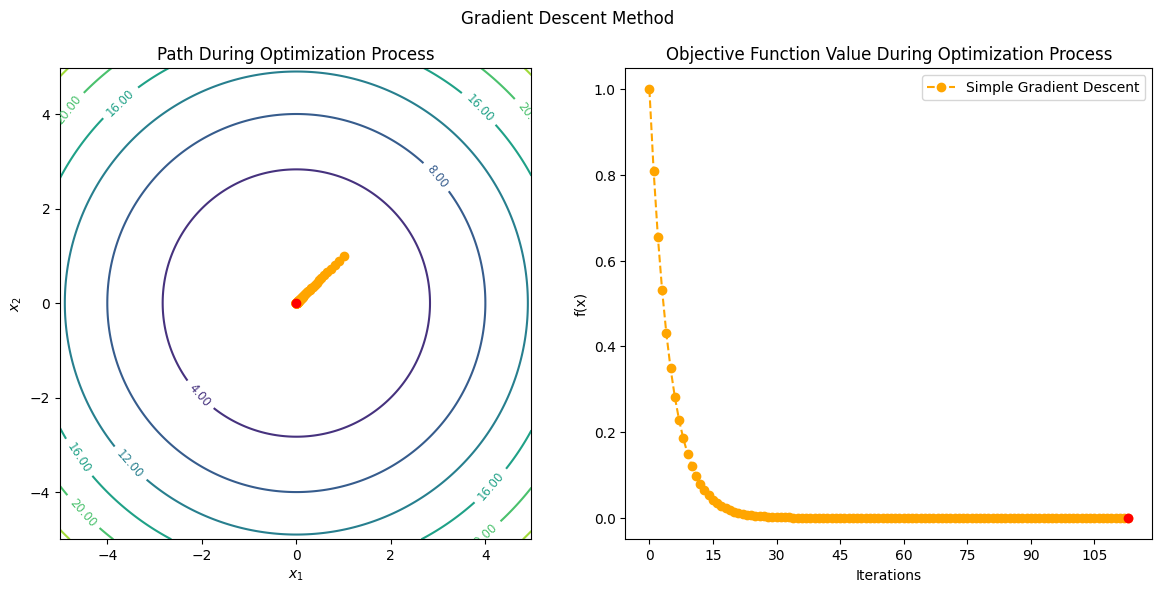

In [6]:
x0=np.array([1.,1])
x_sol,counter,x_simple,y_simple=optimization_path(f2,x0,0.1)
plot_optimization_path(f2,x_simple,y_simple,'Simple Gradient Descent')

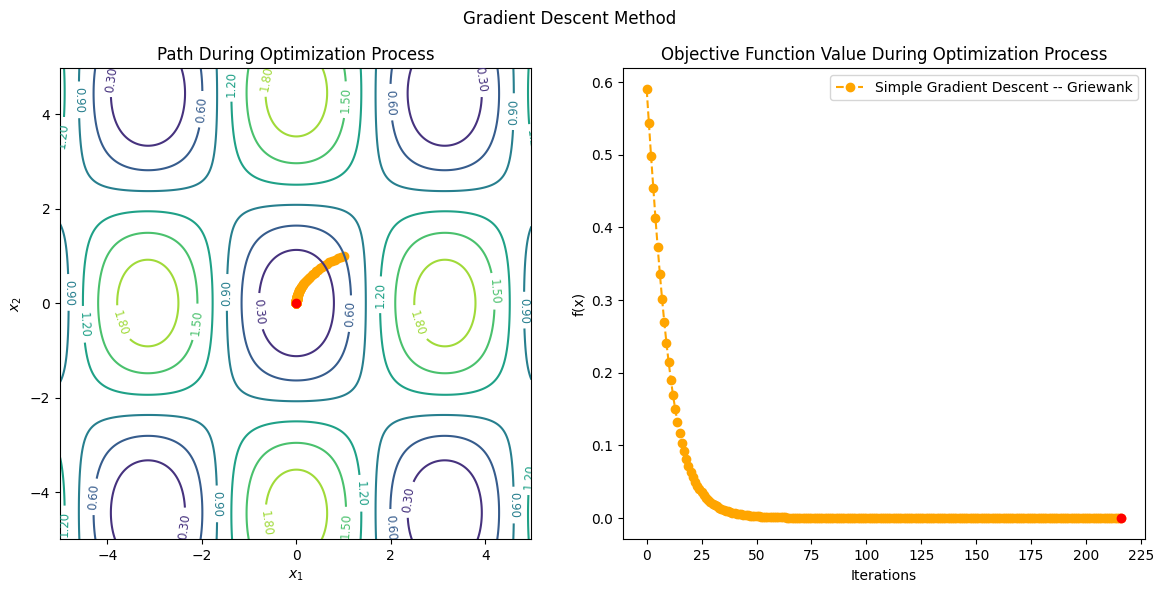

In [7]:
x0=np.array([1.,1])
x_sol,counter,x_simple,y_simple=optimization_path(Griewank,x0,0.1)
plot_optimization_path(Griewank,x_simple,y_simple,'Simple Gradient Descent -- Griewank')

## 5. Line Search: Μέθοδος Χρυσής Τομής

Σε κάθε επανάληψη επιλύουμε:
$$\alpha_k = \arg\min_{\alpha > 0} f(x_k - \alpha \nabla f(x_k))$$

In [8]:
def golden_section(f,a,b,ep=0.00001,max_iter=1000,ep_der=0.00001):

    r=(3-np.sqrt(5))/2
    x1=a+r*(b-a)
    x2=b-r*(b-a)
    f_1=f(x1)
    f_2=f(x2)

    check=1
    counter=0

    while check>ep and counter<max_iter:
        counter=counter+1
        if f_1>f_2:
            a=x1
            x1=x2
            f_1=f_2
            x2=r*a+(1-r)*b
            f_2=f(x2)
        else:
            b=x2
            x2=x1
            f_2=f_1
            x1=r*b+(1-r)*a
            f_1=f(x1)
        check=np.abs(x1-x2)

    x_sol=x1
    f_val=f(x1)

    return x_sol,f_val


def gradient_descent_golden(f,x,ep=0.00001,ep_der=0.00001,max_iter=1000):

    check=1
    counter=0
    x_old=np.asarray(x,dtype=float)
    x_new=x_old.copy()
    curve_x=[x_old]
    curve_f=[f(x_old)]

    while check>ep and counter<max_iter:
        counter=counter+1
        g=grad_f(f,x_old,ep_der)
        f_dir=lambda a: f(x_old-a*g)
        a_best,val=golden_section(f_dir,0,1)
        x_new=x_old-a_best*g
        g_n=grad_f(f,x_new,ep_der)
        check=np.linalg.norm(g_n)
        curve_x.append(x_new)
        curve_f.append(f(x_new))
        x_old=x_new

    x_min=x_new
    f_val=f(x_min)

    return x_min,f_val,counter,np.array(curve_x),np.array(curve_f)

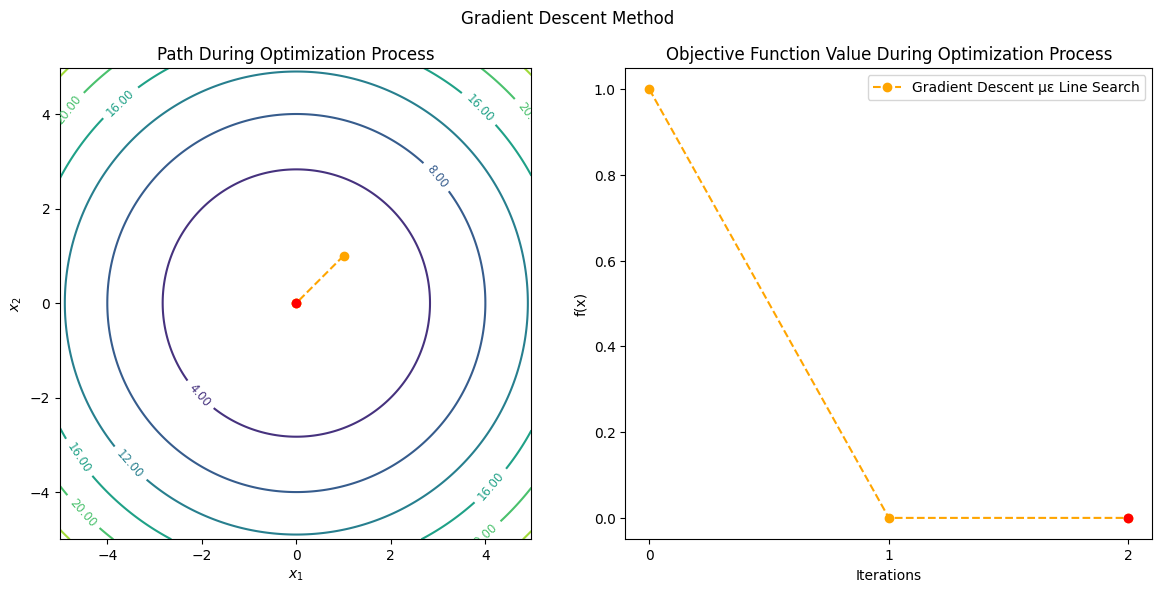

In [9]:
x0=np.array([1.,1])
x_min,f_val,counter,x_ls,y_ls=gradient_descent_golden(f2,x0)
plot_optimization_path(f2,x_ls,y_ls,'Gradient Descent με Line Search')

## 6. Σύγκριση: Σταθερό Βήμα vs Line Search

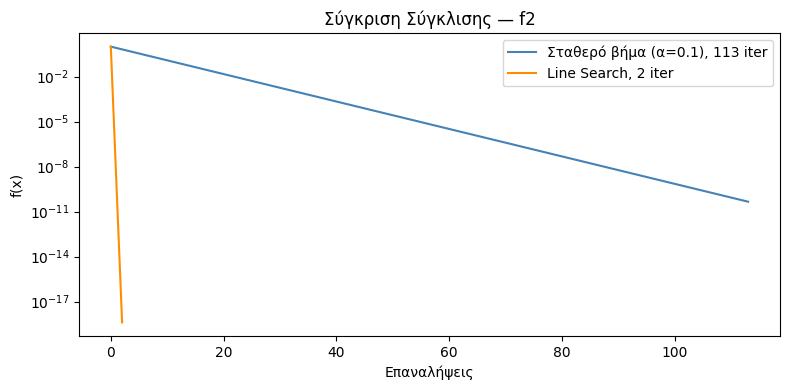

In [10]:
x0=np.array([1.,1])
_,c1,x_s,y_s=optimization_path(f2,x0,0.1)
_,_,c2,x_l,y_l=gradient_descent_golden(f2,x0)

plt.figure(figsize=(8,4))
plt.semilogy(y_s,label=f'Σταθερό βήμα (α=0.1), {c1} iter',color='steelblue')
plt.semilogy(y_l,label=f'Line Search, {c2} iter',color='darkorange')
plt.title('Σύγκριση Σύγκλισης — f2')
plt.xlabel('Επαναλήψεις')
plt.ylabel('f(x)')
plt.legend()
plt.tight_layout()
plt.show()

---
# ΜΕΡΟΣ Β: Stochastic Gradient Descent και Παραλλαγές

Εφαρμογή στη **γραμμική παλινδρόμηση** όπου:
$$L(\theta;X,y)=\frac{1}{n}\|X\theta - y\|^2 = \frac{1}{n}\sum_{i=1}^n L_i(\theta;X_i,y_i)$$

## 7. Παραγωγή Δεδομένων και Συναρτήσεις Loss

In [11]:
def data_generator(b,sig,n_data,p):
    X=np.random.rand(n_data,p)
    epsilon=sig*np.random.randn(n_data)
    y=np.dot(X,b)+epsilon
    return X,y


def grad_loss(c,X,y):
    n=len(y)
    error_vector=np.dot(X,c)-y
    loss=np.mean(error_vector**2)
    grad_c=np.dot(X.T,error_vector)
    grad_c=(2./n)*grad_c
    return loss,grad_c


def grad_loss_one(c,x_vec,y):
    loss_1=(np.dot(c,x_vec)-y)**2
    grad_c_1=2.*(np.dot(c,x_vec)-y)*x_vec
    return loss_1,grad_c_1


b=np.array([1.,2.,3.])
X,y=data_generator(b,0.1,10000,3)
print(f'Αληθινές παράμετροι: {b}')

Αληθινές παράμετροι: [1. 2. 3.]


## 8. Batch Gradient Descent

[1.19127905 1.99808042 2.80757695]


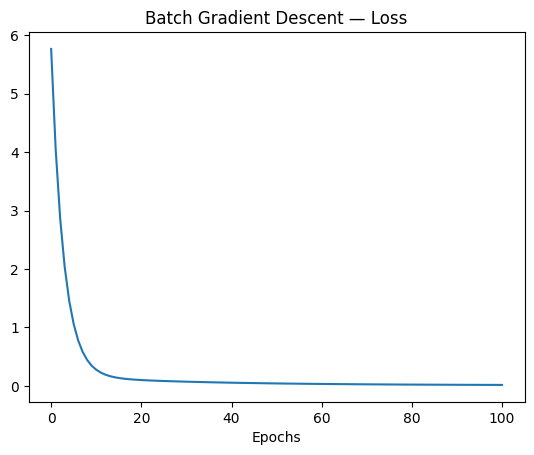

In [12]:
def batch_gradient_descent(c,alpha,X,y,epochs=100):
    loss,grad_c=grad_loss(c,X,y)
    loss_path=[loss]
    for i in range(epochs):
        c=c-alpha*grad_c
        loss,grad_c=grad_loss(c,X,y)
        loss_path.append(loss)
    loss_path=np.array(loss_path)
    c_appr=c
    return c_appr,loss_path


c=np.array([0.5,0.5,0.5])
alpha=0.1
c_appr,loss_path=batch_gradient_descent(c,alpha,X,y)
print(c_appr)
plt.plot(loss_path)
plt.title('Batch Gradient Descent — Loss')
plt.xlabel('Epochs')
plt.show()

## 9. Stochastic Gradient Descent (SGD)

[1.23132385 1.96518755 2.80532   ]


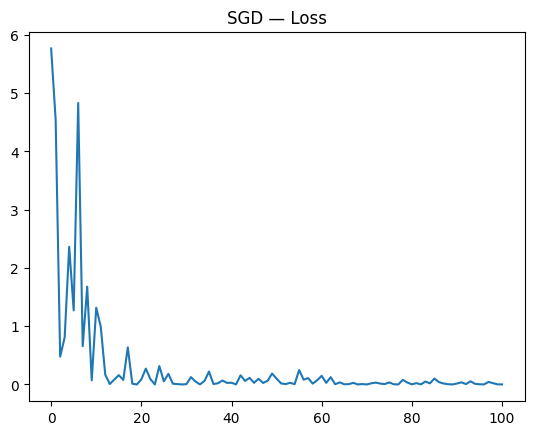

In [13]:
def stochastic_gradient_descent(c,alpha,X,y,n_train,epochs=100):

    n=len(y)
    loss,grad_c=grad_loss(c,X,y)
    loss_path=[loss]

    for i in range(epochs):
        indices=np.arange(n)
        indices_sampled=np.random.choice(indices,n_train,False)
        for index in indices_sampled:
            loss,grad_c=grad_loss_one(c,X[index,:],y[index])
            loss_path.append(loss)
            c=c-alpha*grad_c

    c_appr=c
    loss_path=np.array(loss_path)

    return c_appr,loss_path


c=np.array([0.5,0.5,0.5])
alpha=0.1
c_appr,loss_path=stochastic_gradient_descent(c,alpha,X,y,n_train=10,epochs=10)
print(c_appr)
plt.plot(loss_path)
plt.title('SGD — Loss')
plt.show()

## 10. SGD με Mini-batch

[1.20706116 2.00955879 2.79753283]


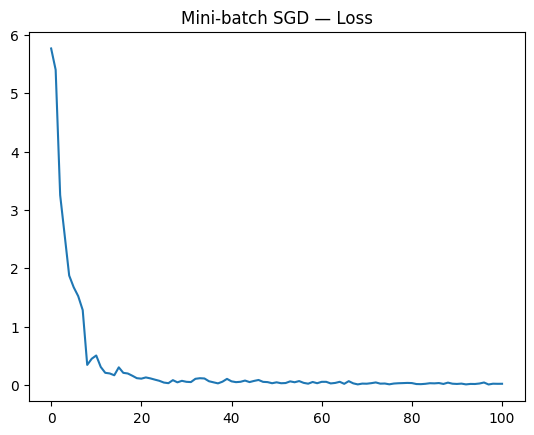

In [14]:
def stochastic_gradient_descent_minibatch(c,alpha,X,y,n_train=10,epochs=100,minibatch=10):

    n=len(y)
    loss,grad_c=grad_loss(c,X,y)
    loss_path=[loss]

    for i in range(epochs):
        indices=np.arange(n)
        indices_sampled=np.random.choice(indices,n_train,False)
        for index in indices_sampled:
            loss,grad_c=grad_loss(c,X[index:index+minibatch,:],y[index:index+minibatch])
            loss_path.append(loss)
            c=c-alpha*grad_c

    c_appr=c
    loss_path=np.array(loss_path)

    return c_appr,loss_path


c=np.array([0.5,0.5,0.5])
alpha=0.1
c_appr,loss_path=stochastic_gradient_descent_minibatch(c,alpha,X,y,n_train=10,epochs=10)
print(c_appr)
plt.plot(loss_path)
plt.title('Mini-batch SGD — Loss')
plt.show()

## 11. Momentum

$$v_{k+1}=\gamma v_{k} + \alpha D_x f(x_k)$$
$$x_{k+1}=x_k - v_{k+1}$$

[0.99972992 2.00741407 2.98424047]
[0.97365319 2.01714907 3.0080166 ]


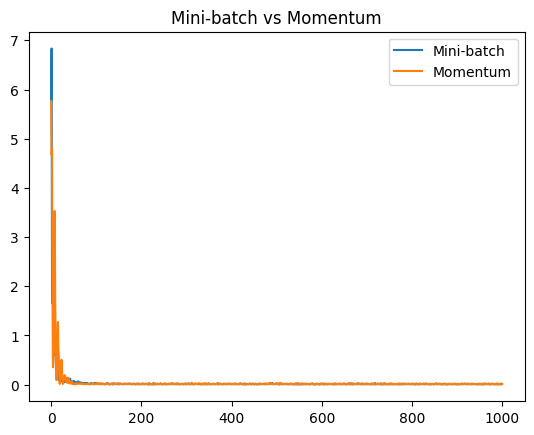

In [15]:
def stochastic_gradient_descent_minibatch_momentum(c,alpha,X,y,n_train=10,epochs=100,minibatch=10,gamma=0.9):

    c=c.copy()
    n=len(y)
    loss,grad_c=grad_loss(c,X,y)
    v=np.zeros_like(c)
    loss_path=[loss]

    for i in range(epochs):
        indices=np.arange(n)
        indices_sampled=np.random.choice(indices,n_train,False)
        for index in indices_sampled:
            loss,grad_c=grad_loss(c,X[index:index+minibatch,:],y[index:index+minibatch])
            loss_path.append(loss)
            v=gamma*v+alpha*grad_c
            c=c-v

    c_appr=c
    loss_path=np.array(loss_path)

    return c_appr,loss_path


c=np.array([0.5,0.5,0.5])
alpha=0.1
n_train=10
c_appr,loss_path=stochastic_gradient_descent_minibatch(c,alpha,X,y,n_train)
print(c_appr)
plt.plot(loss_path)
c_appr,loss_path=stochastic_gradient_descent_minibatch_momentum(c,alpha,X,y,n_train)
print(c_appr)
plt.plot(loss_path)
plt.title('Mini-batch vs Momentum')
plt.legend(['Mini-batch','Momentum'])
plt.show()

## 12. Nesterov Accelerated Gradient

$$v_{k+1}=\gamma v_k + \alpha D_x f(x_k - \gamma v_k)$$
$$x_{k+1}=x_k - v_{k+1}$$

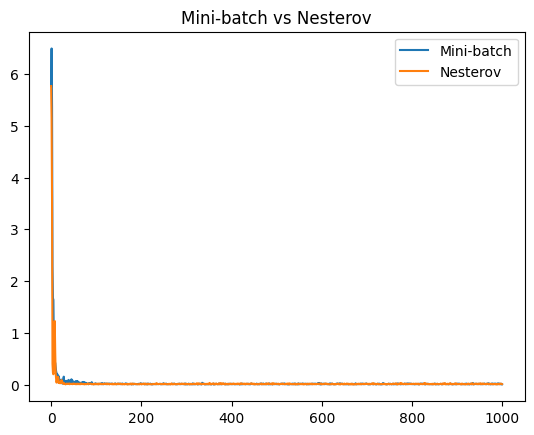

In [16]:
def stochastic_gradient_descent_minibatch_nesterov(c,alpha,X,y,n_train=10,epochs=100,minibatch=10,gamma=0.9):

    c=c.copy()
    n=len(y)
    loss,grad_c=grad_loss(c,X,y)
    v=np.zeros_like(c)
    loss_path=[loss]

    for i in range(epochs):
        indices=np.arange(n)
        indices_sampled=np.random.choice(indices,n_train,False)
        for index in indices_sampled:
            c_temp=c-gamma*v
            loss,grad_c=grad_loss(c_temp,X[index:index+minibatch,:],y[index:index+minibatch])
            loss_path.append(loss)
            v=gamma*v+alpha*grad_c
            c=c-v

    c_appr=c
    loss_path=np.array(loss_path)

    return c_appr,loss_path


c=np.array([0.5,0.5,0.5])
alpha=0.1
n_train=10
c_appr,loss_path=stochastic_gradient_descent_minibatch(c,alpha,X,y,n_train)
plt.plot(loss_path)
c_appr,loss_path=stochastic_gradient_descent_minibatch_nesterov(c,alpha,X,y,n_train)
plt.plot(loss_path)
plt.title('Mini-batch vs Nesterov')
plt.legend(['Mini-batch','Nesterov'])
plt.show()

## 13. AdaGrad

$$G_{k,ii}=\sum_{\tau=1}^k g_{\tau,i}^2$$
$$x_{i,k+1}=x_{i,k} - \frac{\alpha}{\sqrt{G_{k,ii}+\epsilon}}g_{i,k}$$

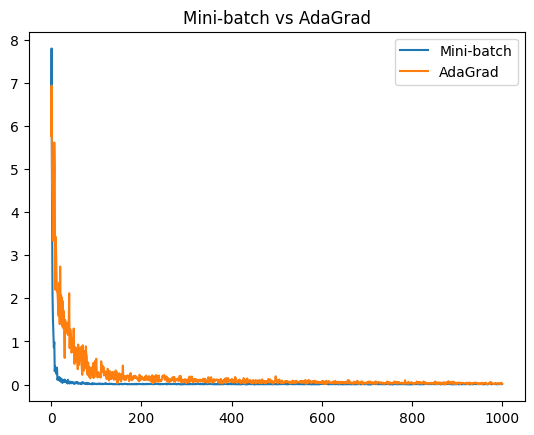

In [17]:
def stochastic_gradient_descent_minibatch_adagrad(c,alpha,X,y,n_train=10,epochs=100,minibatch=10,ep_reg=1e-07):

    c=c.copy()
    n=len(y)
    d=len(c)
    loss,grad_c=grad_loss(c,X,y)
    v=grad_c
    G=np.zeros((d,d))
    loss_path=[loss]

    for i in range(epochs):
        indices=np.arange(n)
        indices_sampled=np.random.choice(indices,n_train,False)
        for index in indices_sampled:
            loss,grad_c=grad_loss(c,X[index:index+minibatch,:],y[index:index+minibatch])
            loss_path.append(loss)
            G=G+np.outer(grad_c,grad_c)
            for j in range(d):
                c[j]=c[j]-(alpha/(np.sqrt(G[j,j]+ep_reg)))*grad_c[j]

    c_appr=c
    loss_path=np.array(loss_path)

    return c_appr,loss_path


c=np.array([0.5,0.5,0.5])
alpha=0.1
n_train=10
c_appr,loss_path=stochastic_gradient_descent_minibatch(c,alpha,X,y,n_train)
plt.plot(loss_path)
c_appr,loss_path=stochastic_gradient_descent_minibatch_adagrad(c,alpha,X,y,n_train)
plt.plot(loss_path)
plt.title('Mini-batch vs AdaGrad')
plt.legend(['Mini-batch','AdaGrad'])
plt.show()

## 14. Adaptive squared-gradient averaging (RMSProp-style)

$$\mathbb{E}[g^2]_k = \gamma\mathbb{E}[g^2]_{k-1} + (1-\gamma)g_k^2$$
$$x_{i,k+1}=x_{i,k} - \frac{\alpha}{\sqrt{\mathbb{E}[g^2]_{k,i}+\epsilon}}g_{i,k}$$

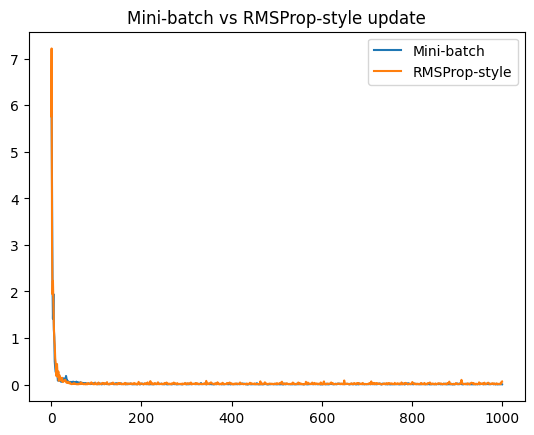

In [18]:
def stochastic_gradient_descent_minibatch_rmsprop(c,alpha,X,y,n_train=10,epochs=100,minibatch=10,gamma=0.9,ep_reg=1e-07):

    c=c.copy()
    n=len(y)
    d=len(c)
    loss,grad_c=grad_loss(c,X,y)
    v=grad_c
    G=np.zeros((d,d))
    loss_path=[loss]

    for i in range(epochs):
        indices=np.arange(n)
        indices_sampled=np.random.choice(indices,n_train,False)
        for index in indices_sampled:
            loss,grad_c=grad_loss(c,X[index:index+minibatch,:],y[index:index+minibatch])
            loss_path.append(loss)
            G=gamma*G+(1-gamma)*np.diag(grad_c**2)
            for j in range(d):
                c[j]=c[j]-(alpha/(np.sqrt(G[j,j]+ep_reg)))*grad_c[j]

    c_appr=c
    loss_path=np.array(loss_path)

    return c_appr,loss_path


c=np.array([0.5,0.5,0.5])
alpha=0.1
n_train=10
c_appr,loss_path=stochastic_gradient_descent_minibatch(c,alpha,X,y,n_train)
plt.plot(loss_path)
c_appr,loss_path=stochastic_gradient_descent_minibatch_rmsprop(c,alpha,X,y,n_train)
plt.plot(loss_path)
plt.title('Mini-batch vs RMSProp-style update')
plt.legend(['Mini-batch','RMSProp-style'])
plt.show()

## 15. Adam

$$m_{k+1}=\beta_1 m_k + (1-\beta_1)g_k, \quad u_{k+1}=\beta_2 u_k + (1-\beta_2)g_k^2$$
$$\hat{m}_k=\frac{m_k}{1-\beta_1^k}, \quad \hat{u}_k=\frac{u_k}{1-\beta_2^k}$$
$$x_{k+1}=x_k - \frac{\alpha}{\sqrt{\hat{u}_k+\epsilon}}\hat{m}_k$$

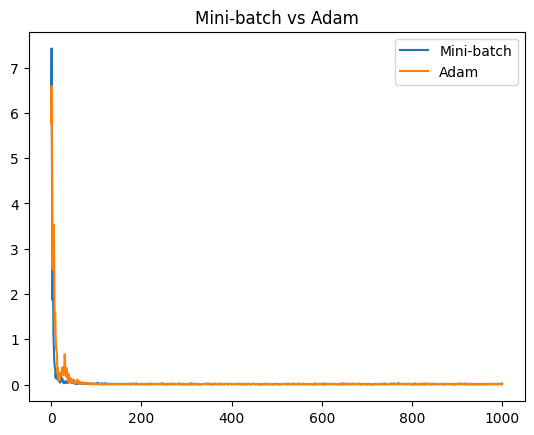

In [19]:
def stochastic_gradient_descent_minibatch_adam(c,alpha,X,y,n_train,epochs=100,minibatch=10,beta_1=0.9,beta_2=0.999,ep_reg=1e-07):

    c=c.copy()
    n=len(y)
    d=len(c)
    loss,grad_c=grad_loss(c,X,y)
    v=grad_c
    k=0
    G_1=np.zeros((d,d))
    G_2=np.zeros((d,d))
    loss_path=[loss]

    for i in range(epochs):
        indices=np.arange(n)
        indices_sampled=np.random.choice(indices,n_train,False)
        for index in indices_sampled:
            loss,grad_c=grad_loss(c,X[index:index+minibatch,:],y[index:index+minibatch])
            loss_path.append(loss)
            G_1=beta_1*G_1+(1-beta_1)*np.diag(grad_c)
            G_2=beta_2*G_2+(1-beta_2)*np.diag(grad_c**2)
            k+=1
            hatG_1=(1/(1-beta_1**k))*G_1
            hatG_2=(1/(1-beta_2**k))*G_2
            for j in range(d):
                c[j]=c[j]-(alpha/(np.sqrt(hatG_2[j,j]+ep_reg)))*hatG_1[j,j]

    c_appr=c
    loss_path=np.array(loss_path)

    return c_appr,loss_path


c=np.array([0.5,0.5,0.5])
alpha=0.1
n_train=10
c_appr,loss_path=stochastic_gradient_descent_minibatch(c,alpha,X,y,n_train)
plt.plot(loss_path)
c_appr,loss_path=stochastic_gradient_descent_minibatch_adam(c,alpha,X,y,n_train)
plt.plot(loss_path)
plt.title('Mini-batch vs Adam')
plt.legend(['Mini-batch','Adam'])
plt.show()

---
# Συμπεράσματα

**Μέθοδοι γενικής βελτιστοποίησης:**
- Το gradient descent με σταθερό βήμα είναι απλό αλλά ευαίσθητο στην επιλογή $\alpha$.
- Η line search (χρυσή τομή) επιλέγει αυτόματα βέλτιστο $\alpha_k$ σε κάθε βήμα και συγκλίνει ταχύτερα.

**Μέθοδοι SGD:**
- Το mini-batch SGD προσφέρει καλή ισορροπία μεταξύ υπολογιστικού κόστους και ακρίβειας.
- Το Momentum και το Nesterov επιταχύνουν τη σύγκλιση εξομαλύνοντας την τροχιά.
- Το AdaGrad προσαρμόζει αυτόματα το learning rate ανά παράμετρο.
- Το RMSProp-style βελτιώνει το AdaGrad αποφεύγοντας τη συνεχή μείωση του learning rate.
- Το Adam συνδυάζει momentum και προσαρμοστικό learning rate και είναι η πιο αποτελεσματική μέθοδος στην πράξη.

**Βιβλιογραφία:**
- Ruder, S. (2016). An overview of gradient descent optimization algorithms. arXiv:1609.04747
- Lan, G. (2020). First-order and stochastic optimization methods for machine learning. Springer

## Full-data MSE comparison
Equal number of updates (not equal computational cost); reset seed for each stochastic method.

In [20]:
methods = {
    "Batch GD": lambda c: batch_gradient_descent(c, 0.1, X, y, epochs=100),
    "SGD": lambda c: stochastic_gradient_descent(c, 0.1, X, y, n_train=10, epochs=10),
    "Mini-batch": lambda c: stochastic_gradient_descent_minibatch(c, 0.1, X, y, n_train=10, epochs=10),
    "Momentum": lambda c: stochastic_gradient_descent_minibatch_momentum(c, 0.1, X, y, n_train=10, epochs=10),
    "Nesterov": lambda c: stochastic_gradient_descent_minibatch_nesterov(c, 0.1, X, y, n_train=10, epochs=10),
    "AdaGrad": lambda c: stochastic_gradient_descent_minibatch_adagrad(c, 0.1, X, y, n_train=10, epochs=10),
    "RMSProp-style": lambda c: stochastic_gradient_descent_minibatch_rmsprop(c, 0.1, X, y, n_train=10, epochs=10),
    "Adam": lambda c: stochastic_gradient_descent_minibatch_adam(c, 0.1, X, y, n_train=10, epochs=10),
}
print(f"{'Method':16} {'Full MSE':>12} {'Parameter error':>16}")
for name, fit in methods.items():
    np.random.seed(42)
    estimate, _ = fit(np.full(3, 0.5))
    print(f"{name:16} {np.mean((X @ estimate-y)**2):12.6f} {np.linalg.norm(estimate-b):16.6f}")

Method               Full MSE  Parameter error
Batch GD             0.016043         0.271326
SGD                  0.017215         0.258290
Mini-batch           0.015259         0.252869
Momentum             0.010611         0.068690
Nesterov             0.010371         0.061800
AdaGrad              0.307023         1.364093
RMSProp-style        0.011113         0.038078
Adam                 0.013227         0.192552


In [21]:
# Numerical smoke checks.
np.testing.assert_allclose(grad_f(f2, np.array([1, 2])), [1, 2], atol=1e-5)
np.testing.assert_allclose(hessian_f(f2, np.array([1, 2])), np.eye(2), atol=1e-4)
assert np.allclose(optimization_path(f2, np.array([1, 2]), max_iter=0)[0], [1, 2])
print("Numerical checks passed.")

Numerical checks passed.
